# 01 · Data Cleaning, Validation & Feature Engineering
**Customer Revenue Intelligence** — Step 3

> ⚠️ **SYNTHETIC DATA.** This notebook cleans the dataset generated in Step 2 (seed 42). No real customers or transactions are represented.

This notebook runs the functions in `src/data_cleaning.py` one by one, so each cleaning decision can be seen together with its effect. Every number shown comes from the code output; the explanation cells describe the *method*, not the results.

**Pipeline:** Load → Audit → Duplicates → Types → Categories → Numeric validation → Missing values → Business rules → Outliers → Customer validation → Features → Leakage check → Before/After → Save

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import pandas as pd
import config
from src import data_cleaning as dc

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

## 1. Load the raw data
Every column is read as **text** first, so values such as `₹1,299` or `15` (a percentage) are seen exactly as stored, before any automatic conversion hides them.

In [2]:
raw = dc.load_data()
profile = dc.describe_raw(raw)
print(f"Shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
profile["head"]

Shape: 18,819 rows x 23 columns


,Order_Line_ID,Order_ID,Order_Date,Customer_ID,Customer_Name,Customer_Age,Gender,City,State,Region,Product_ID,Product_Name,Category,Sub_Category,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Order_Status,Customer_Type
0,OL-0000001,ORD-000001,2023-01-01,CUST-0146,Tanvi Mishra,30,Female,Kanpur,Uttar Pradesh,North,BEA-006,Matte Lipstick,Beauty,Makeup,2,606.0,0.2,969.6,435.83,533.77,UPI,Delivered,Returning
1,OL-0000002,ORD-000001,01/01/2023,CUST-0146,Tanvi Mishra,30,Female,Kanpur,Uttar Pradesh,North,FAS-006,Running Shoes,Fashion,Footwear,1,2982.0,0.2,2385.6,1567.63,817.97,UPI,Delivered,Returning
2,OL-0000003,ORD-000002,2023-01-01,CUST-1296,Sandeep Mishra,24,Male,Surat,Gujarat,West,FAS-007,Casual Sneakers,Fashion,Footwear,2,2155.0,0.25,3232.5,2131.67,1100.83,Wallet,Delivered,Returning
3,OL-0000004,ORD-000003,2023-01-01,CUST-1405,Moumita Bhatia,51,Female,Guwahati,Assam,East,HOM-005,Non-Stick Cookware Set,Home & Kitchen,Cookware,1,2307.0,0.2,1845.6,1336.42,509.18,Net Banking,Delivered,Returning
4,OL-0000005,ORD-000003,2023-01-01,CUST-1405,Moumita Bhatia,51,Female,Guwahati,Assam,East,FAS-004,Women's Cotton Saree,Fashion,Women's Clothing,1,2476.0,0.2,1980.8,1245.26,735.54,Net Banking,Delivered,Returning
5,OL-0000006,ORD-000003,2023-01-01,CUST-1405,Moumita Bhatia,51,Female,Guwahati,Assam,East,HOM-001,Mixer Grinder 750W,Home & Kitchen,Kitchen Appliances,1,3476.0,0.2,2780.8,2280.18,500.62,Net Banking,Delivered,Returning
6,OL-0000007,ORD-000004,2023-01-01,CUST-1671,Ishaan Panda,18,Male,Bombay,Maharashtra,West,FAS-008,Leather Formal Shoes,Fashion,Footwear,2,3542.0,0.35,4604.6,4016.93,587.67,COD,Returned,Returning
7,OL-0000008,ORD-000005,2023-01-01,CUST-1744,Aniket Panda,25,Male,Kolkata,West Bengal,East,FAS-003,Women's Printed Kurta,Fashion,Women's Clothing,2,1191.0,0.0,2382.0,1003.21,1378.79,Net Banking,Delivered,New
8,OL-0000009,ORD-000006,2023-01-01,CUST-1772,Nitin Hazarika,27,Male,Gurugram,Haryana,North,HOM-001,Mixer Grinder 750W,Home & Kitchen,Kitchen Appliances,1,3507.0,0.05,3331.65,2332.65,999.0,UPI,Delivered,Returning
9,OL-0000010,ORD-000006,2023-01-01,CUST-1772,Nitin Hazarika,27,Male,Gurugram,Haryana,North,HOM-011,Airtight Container Set,Home & Kitchen,Storage,1,878.0,0.0,878.0,482.05,395.95,UPI,Delivered,Returning


In [3]:
profile['tail']

,Order_Line_ID,Order_ID,Order_Date,Customer_ID,Customer_Name,Customer_Age,Gender,City,State,Region,Product_ID,Product_Name,Category,Sub_Category,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Order_Status,Customer_Type
18809,OL-0018661,ORD-013245,2025-12-31,CUST-0520,Sneha Nair,28,Female,Surat,Gujarat,West,BEA-004,Argan Oil Shampoo,Beauty,Haircare,1,499.0,0.2,399.2,207.88,191.32,Card,Delivered,Returning
18810,OL-0018662,ORD-013246,2025-12-31,CUST-0636,Joseph Verma,18,Male,Guwahati,Assam,East,HOM-002,Air Fryer 4L,Home & Kitchen,Kitchen Appliances,2,6812.0,0.2,10899.2,9216.71,1682.49,Wallet,Delivered,Returning
18811,OL-0018663,ORD-013246,2025-12-31,CUST-0636,Joseph Verma,18,Male,Guwahati,Assam,East,FAS-004,Women's Cotton Saree,Fashion,Women's Clothing,1,2904.0,0.3,2032.8,1451.41,581.39,Wallet,Delivered,Returning
18812,OL-0018664,ORD-013247,2025-12-31,CUST-0658,Mohit Verma,35,Male,Bengaluru,Karnataka,South,FAS-004,Women's Cotton Saree,Fashion,Women's Clothing,1,2925.0,0.35,1901.25,1458.77,442.48,Net Banking,Delivered,Returning
18813,OL-0018665,ORD-013248,2025-12-31,CUST-0813,Rakesh D'Souza,34,Male,Pune,Maharashtra,West,SPO-005,English Willow Cricket Bat,Sports,Team Sports,1,5250.0,0.2,4200.0,3132.43,1067.57,Card,Delivered,Returning
18814,OL-0018666,ORD-013248,2025-12-31,CUST-0813,Rakesh D'Souza,34,Male,Pune,Maharashtra,West,BEA-003,Hydrating Face Moisturiser,Beauty,Skincare,1,455.0,0.2,364.0,183.04,180.96,Card,Delivered,Returning
18815,OL-0018667,ORD-013248,2025-12-31,CUST-0813,Rakesh D'Souza,34,Male,Pune,Maharashtra,West,HOM-009,Decorative Table Lamp,Home & Kitchen,Home Decor,2,1574.0,0.15,2675.8,1747.3,928.5,Card,Delivered,Returning
18816,OL-0018668,ORD-013249,2025-12-31,CUST-1240,Ananya Fernandes,43,Female,Bengaluru,Karnataka,South,FAS-001,Men's Cotton Casual Shirt,Fashion,Men's Clothing,1,1516.0,0.2,1212.8,685.97,526.83,Net Banking,Delivered,Returning
18817,OL-0018669,ORD-013250,2025-12-31,CUST-1838,Rohan Saikia,20,Male,Coimbatore,Tamil Nadu,South,HOM-011,Airtight Container Set,Home & Kitchen,Storage,1,1062.0,0.3,743.4,572.47,170.93,Card,Delivered,Returning
18818,OL-0018670,ORD-013251,2025-12-31,CUST-1894,Deepika Sandhu,36,Female,Chennai,Tamil Nadu,South,HOM-004,Microwave Oven 20L,Home & Kitchen,Kitchen Appliances,1,8932.0,0.2,7145.6,6483.03,662.57,Card,Delivered,Returning


### Data types as pandas infers them, and the role of each column
`Unit_Price` is read as text (some values contain `₹` and commas) and `Customer_Age` as float (missing values force floats). `Order_Date` is read as text because several date formats are mixed.

In [4]:
profile['roles']

,Column,Role,Type as read by pandas
0,Order_Line_ID,Identifier,str
1,Order_ID,Identifier,str
2,Order_Date,Date,str
3,Customer_ID,Identifier,str
4,Customer_Name,Categorical,str
5,Customer_Age,Numerical,float64
6,Gender,Categorical,str
7,City,Categorical,str
8,State,Categorical,str
9,Region,Categorical,str


In [5]:
profile['numeric_stats']

,count,mean,std,min,25%,50%,75%,max
Customer_Age,18534.0,34.10,18.19,0.00,27.00,34.00,39.00,999.00
Quantity,18819.0,1.35,1.38,-1.00,1.00,1.00,1.00,50.00
Discount,18726.0,0.16,0.85,0.00,0.00,0.10,0.20,35.00
Sales,18763.0,3551.86,7646.67,219.05,1023.10,1717.85,3110.40,176942.00
Cost,18819.0,2714.69,7216.37,127.85,556.14,1049.36,1973.11,167369.26
Profit,18819.0,834.36,1098.49,-14964.80,392.92,644.04,1019.64,45435.74


In [6]:
profile['text_stats']

,count,unique,top,freq
Order_Line_ID,18819,18670,OL-0000103,2
Order_ID,18819,13251,ORD-000078,4
Order_Date,18819,1573,2025-10-17,56
Customer_ID,18819,2000,CUST-1128,54
Customer_Name,18819,1707,Suresh Menon,70
Gender,18631,11,Male,10038
City,18670,41,Hyderabad,1150
State,18819,26,Maharashtra,2231
Region,18819,20,South,5076
Product_ID,18819,61,FAS-003,947


## 2. Data-quality audit
Each issue is **measured**, not assumed. Checks that found zero problems are kept in the table to show they were run.

In [7]:
before_profile = dc.dataset_profile(raw)
audit = dc.audit_data(raw)
audit

,Issue,Column,Affected_Records,Percent_Affected,Treatment
0,Missing value,Customer_Age,285,1.51,Restore from the same customer's other rows (one profile per customer); median only as...
1,Missing value,Gender,188,1.00,Restore from the same customer's other rows
2,Missing value,City,149,0.79,Restore from the same customer's other rows
3,Missing value,Discount,93,0.49,Back-calculate: 1 - Sales / (Quantity x Unit_Price)
4,Missing value,Sales,56,0.30,"Recompute exactly as Cost + Profit, then confirm against Qty x Price x (1 - Discount)"
5,Missing value,Payment_Method,189,1.00,Copy from other lines of the same order; otherwise label 'Unknown'
6,Exact duplicate row,All columns,149,0.79,Remove (keep first occurrence)
7,Duplicate Order_Line_ID with different content,Order_Line_ID,0,0.00,No action needed (check passed)
8,Order_ID repeated across rows (multi-product orders),Order_ID,9633,51.19,Keep - legitimate: one order can contain several products
9,Customer profile differs across rows,Customer_ID,319,1.70,Harmonise to the customer's most frequent (modal) value


## 3. Duplicate handling
Three kinds of repetition need to be told apart:

| Type | Meaning | Treatment |
|---|---|---|
| **Row-level duplicate** | Every column identical, including `Order_Line_ID` — the same record was loaded twice | **Remove** |
| **Order-level repetition** | Same `Order_ID` on several rows — one checkout containing several products | **Keep** (legitimate) |
| **Customer-level repetition** | Same `Customer_ID` on many orders — a repeat buyer | **Keep** (this is what RFM measures) |

A fourth, weaker case — same order, product, quantity and price on two different line IDs — is only **flagged** (`Potential_Duplicate_Flag`), because a customer can legitimately add the same item twice.

In [8]:
df, dup_info = dc.remove_duplicates(raw)
pd.Series(dup_info, name="Value").to_frame()

,Value
rows_before,18819
exact_duplicates_removed,149
rows_after,18670
remaining_duplicate_line_ids,0


## 4. Data type standardisation
* `Order_Date`: each known format is parsed **explicitly** (ISO, then DD-MM-YYYY, then DD/MM/YYYY). Guessing the format could swap day and month.
* Numbers: `₹` and commas are stripped before conversion.
* IDs: trimmed and upper-cased.

In [9]:
df, type_info = dc.standardize_types(df)
display(pd.Series(type_info, name="Rows").to_frame())
df[["Order_Date", "Unit_Price", "Quantity", "Discount", "Sales"]].dtypes.to_frame("dtype")

,Rows
rows_dropped_unparseable_date,0
dates_reformatted,560
prices_converted_from_text,93


,dtype
Order_Date,datetime64[ns]
Unit_Price,Float64
Quantity,Int64
Discount,Float64
Sales,Float64


## 5. Categorical standardisation
Spaces are trimmed, case is fixed, and spelling variants are mapped to one standard value. Former city and state names (for example Bombay → Mumbai, Orissa → Odisha) are mapped to current official names.

In [10]:
df, cat_compare = dc.standardize_categories(df)
cat_compare

,Column,Unique_Before,Unique_After,Values_After (up to 12)
0,Customer_Name,1707,1621,"Aarav Agarwal, Aarav Bose, Aarav Das, Aarav Desai, Aarav Dutta, Aarav Fernandes, Aarav..."
1,Gender,11,3,"Female, Male, Other"
2,City,41,34,"Ahmedabad, Amritsar, Bengaluru, Bhopal, Bhubaneswar, Chandigarh, Chennai, Coimbatore, ..."
3,State,26,21,"Andhra Pradesh, Assam, Bihar, Chandigarh, Chhattisgarh, Delhi, Goa, Gujarat, Haryana, ..."
4,Region,20,5,"Central, East, North, South, West"
5,Product_Name,61,61,"20000mAh Power Bank, 43-inch 4K Smart TV, 65W Fast Charger, Adjustable Dumbbell Set 20..."
6,Category,24,6,"Beauty, Books, Electronics, Fashion, Home & Kitchen, Sports"
7,Sub_Category,26,26,"Academic, Accessories, Audio, Children, Cookware, Cycling, Fashion Accessories, Fictio..."
8,Payment_Method,15,5,"COD, Card, Net Banking, UPI, Wallet"
9,Order_Status,3,3,"Cancelled, Delivered, Returned"


In [11]:
# Before -> after for the most affected columns
for col in ["Category", "Region", "Gender", "Payment_Method"]:
    print(f"{col}\n  before: {sorted(raw[col].dropna().unique())}\n  after : {sorted(df[col].dropna().unique())}\n")

Category
  before: [' Beauty', ' Books', ' Electronics ', 'BEAUTY', 'BOOKS', 'Beauty', 'Books', 'ELECTRONICS', 'Electronics', 'FASHION', 'Fashion', 'Fashion ', 'Home & Kitchen', 'Home & Kitchen ', 'Home and Kitchen', 'SPORTS', 'Sports', 'Sports ', 'beauty', 'books', 'electronics', 'fashion', 'home & kitchen', 'sports']
  after : ['Beauty', 'Books', 'Electronics', 'Fashion', 'Home & Kitchen', 'Sports']

Region
  before: [' Central', ' East', ' North', ' South', ' West', 'CENTRAL', 'Central', 'EAST', 'East', 'NORTH', 'North', 'SOUTH', 'South', 'WEST', 'West', 'central', 'east', 'north', 'south', 'west']
  after : ['Central', 'East', 'North', 'South', 'West']

Gender
  before: ['F', 'FEMALE', 'Female', 'M', 'MALE', 'Male', 'O', 'Other', 'female', 'male', 'other']
  after : ['Female', 'Male', 'Other']

Payment_Method
  before: ['COD', 'Card', 'Cash on Delivery', 'Credit/Debit Card', 'E-Wallet', 'Net Banking', 'NetBanking', 'UPI', 'Upi', 'Wallet', 'card', 'cod', 'net banking', 'upi', 'walle

## 6. Numerical validation
Business ranges: age 18–100, discount between 0 and the 40% policy cap, quantity and price > 0.
* Values that are clearly **errors** become missing, so they can be recovered in the next step, and each one is flagged.
* A discount between 1 and 100 is read as a **percentage** and divided by 100.
* Large but internally consistent values (for example bulk quantities) are **not** changed here; they are examined in the outlier step.

In [12]:
df, num_info = dc.validate_numeric_fields(df)
pd.Series(num_info, name="Rows").to_frame()

,Rows
ages_out_of_range_set_missing,19
discounts_rescaled_from_percent,37
discounts_invalid_set_missing,0
quantities_not_positive_set_missing,9
prices_not_positive_set_missing,0


## 7. Missing-value handling
Treatments are applied in order of reliability. Nothing is filled with zero.

| Column | Why it may be missing | Treatment | Reasoning |
|---|---|---|---|
| Customer_Age, Gender, City, Customer_Name | Form field skipped on one order | Customer's **modal value** from their other rows | A customer has one profile; their own records beat any population average |
| Customer_Age (no other record) | — | Median age, flagged | Last resort; affects very few rows |
| Gender, City (no other record) | — | `Unknown` | Guessing a person's gender or city would invent data |
| State, Region | — | Derived from City | Fixed geographic hierarchy |
| Payment_Method | Gateway did not return a value | Copy from other lines of the **same order**, else `Unknown` | Payment is chosen once per checkout |
| Sales | Field lost in export | **Sales = Cost + Profit** (exact identity) | Exact, not estimated |
| Discount | Field lost in export | 1 − Sales ÷ (Quantity × Unit_Price) | Exact rearrangement of the revenue formula |
| Quantity (invalid) | Entry error | Sales ÷ (Unit_Price × (1 − Discount)), only if a whole number | Accept only if the result makes sense |

In [13]:
df, missing_log = dc.handle_missing_values(df)
missing_log

,Column,Missing_Before,Missing_After,Recovered,Method
0,Customer_Name,0,0,0,Customer's modal value from their other transactions
1,Customer_Age,299,1,298,Customer's modal value from their other transactions
2,Gender,187,1,186,Customer's modal value from their other transactions
3,City,149,1,148,Customer's modal value from their other transactions
4,Customer_Age,1,0,1,Median age (no other record for the customer)
5,Gender,1,0,1,Labelled 'Unknown' (customer has no other record)
6,City,1,0,1,Labelled 'Unknown' (customer has no other record; State/Region kept)
7,State,0,0,0,Derived from City (reference hierarchy)
8,Region,0,0,0,Derived from State (reference hierarchy)
9,Payment_Method,187,0,187,Copied from same order's other lines; else 'Unknown'


## 8. Business-logic validation
**First report, then correct.** Rows breaking `Sales = Qty × Price × (1 − Discount)` are diagnosed:
* Sales is trusted when it agrees with `Cost + Profit`, which is an independent identity.
* If `Qty × Price × (1 − D)` is about 10× Sales, the unit price has a **decimal-shift typo** (an extra zero), so the price is recomputed.

Every row keeps `Revenue_Check_Pass` and `Profit_Check_Pass` flags.

In [14]:
print("Before correction:", dc.business_rule_check(df)[["Revenue_Check_Pass", "Profit_Check_Pass"]].eq(False).sum().to_dict())
df, biz_info = dc.validate_business_rules(df)
pd.Series(biz_info, name="Rows").to_frame()

Before correction: {'Revenue_Check_Pass': 9, 'Profit_Check_Pass': 0}


,Rows
revenue_failures_before,9
profit_failures_before,0
prices_corrected_decimal_shift,9
revenue_failures_after,0
profit_failures_after,0


## 9. Outlier analysis — flag, don't delete
Three methods are compared: the IQR rule, the z-score (|z| > 3), and business thresholds (≥ 10 units = bulk; Profit < 0 = loss-making).

Why extremes are kept: high-value lines are often the most important customers and products. Removing them would understate revenue and hide exactly the patterns that segmentation and CLV analysis are meant to find.

In [15]:
df["Potential_Duplicate_Flag"] = dc.flag_potential_duplicates(df)
df, outlier_summary = dc.detect_outliers(df)
outlier_summary

,Variable,Q1,Q3,IQR,Lower_Fence,Upper_Fence,IQR_Outliers,IQR_Outlier_%,Z>3_Outliers,Min,Max,Skewness,Note
0,Sales,1024.58,3111.00,2086.43,-2105.06,6240.64,1960,10.50,368,219.05,176942.00,8.07,Right-skewed: a minority of premium-product lines sit above the fence
1,Profit,392.70,1019.69,627.00,-547.80,1960.18,1400,7.50,239,-14964.80,45435.74,10.47,"Both tails: large profits on premium items, losses on deep discounts"
2,Quantity,1.00,1.00,0.00,1.00,1.00,4578,24.52,19,1.00,50.00,24.62,"IQR rule degenerate (Q1 = Q3 = 1, so every line with 2+ units is 'outside'); use z-sco..."
3,Unit_Price,916.00,2718.00,1802.00,-1787.00,5421.00,1936,10.37,349,291.00,98119.00,7.01,Reflects the product price list (Rs 291 - Rs 98k); extremes are premium products


In [16]:
dc.explain_outliers(df)

,Group,Rows,Share_of_Gross_Sales_%,Top_Categories,Interpretation
0,High-value lines (Sales above IQR fence),1960,52.7,"Electronics, Home & Kitchen, Fashion","Premium products (phones, laptops, TVs) - legitimate; they carry a large share of revenue"
1,Bulk lines (Quantity >= 10),19,1.3,"Home & Kitchen, Fashion, Beauty","Formulas hold exactly, so not errors - likely gifting / institutional purchases; keep ..."
2,Loss-making lines (Profit < 0),271,9.8,"Electronics, Home & Kitchen, Sports","Deep discounts on thin-margin items - a business issue to study in EDA, not a data error"


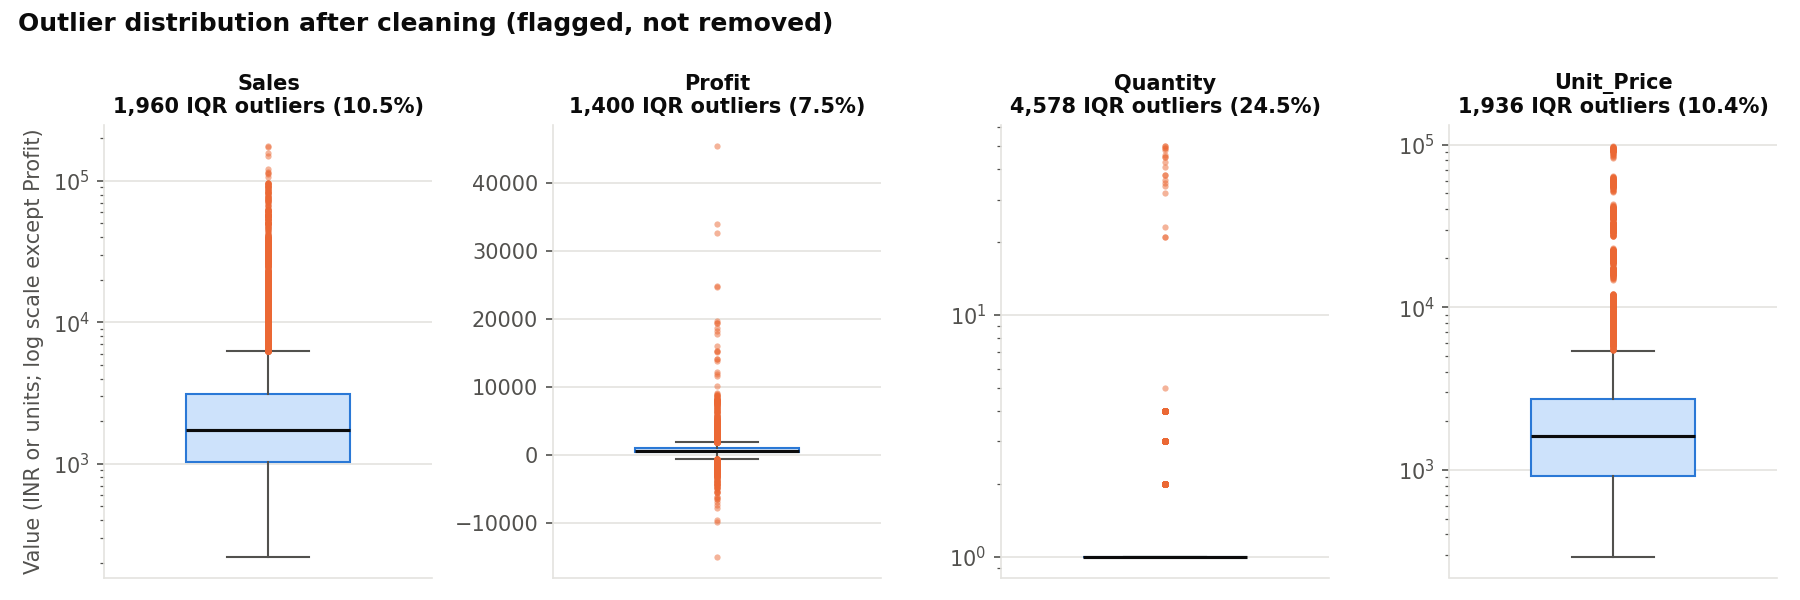

In [17]:
from IPython.display import Image
Image(str(config.DQ_FIGURES_DIR / "03_outlier_distribution.png")) if (config.DQ_FIGURES_DIR / "03_outlier_distribution.png").exists() else "Run the pipeline cell below to create charts"

## 10. Feature engineering
Transaction-level features: date parts, `Gross_Amount`, `Discount_Amount`, `Revenue` / `Net_Profit` (**Delivered lines only**, the project's revenue rule), `Profit_Margin`, `Discount_Band`, `Age_Band` and `Order_Line_Count`.

In [18]:
df = dc.create_features(df).sort_values("Order_Line_ID").reset_index(drop=True)
df[["Order_Date", "Order_Year", "Order_Quarter", "Order_Month", "Year_Month", "Order_Week",
    "Day_of_Week", "Gross_Amount", "Discount_Amount", "Revenue", "Profit_Margin", "Discount_Band", "Age_Band"]].head()

,Order_Date,Order_Year,Order_Quarter,Order_Month,Year_Month,Order_Week,Day_of_Week,Gross_Amount,Discount_Amount,Revenue,Profit_Margin,Discount_Band,Age_Band
0,2023-01-01,2023,Q1,January,2023-01,52,Sunday,1212.0,242.4,969.6,0.5505,11-20%,25-34
1,2023-01-01,2023,Q1,January,2023-01,52,Sunday,2982.0,596.4,2385.6,0.3429,11-20%,25-34
2,2023-01-01,2023,Q1,January,2023-01,52,Sunday,4310.0,1077.5,3232.5,0.3406,21-30%,18-24
3,2023-01-01,2023,Q1,January,2023-01,52,Sunday,2307.0,461.4,1845.6,0.2759,11-20%,50+
4,2023-01-01,2023,Q1,January,2023-01,52,Sunday,2476.0,495.2,1980.8,0.3713,11-20%,50+


## 11. Customer-level validation and features
Customer-level descriptive features: total revenue, total orders, AOV and purchase frequency. These are **not** RFM scores, which come in Step 5.

Purchase frequency = delivered orders per 30 days of observed tenure.

In [19]:
customers = dc.build_customer_features(df)
cust_stats, unusual = dc.customer_validation(customers)
display(cust_stats)
print(f"Unusual customer records: {len(unusual)}")
unusual["Reason"].str.replace(r"\(INR.*\)", "", regex=True).value_counts().to_frame("Customers")

,Metric,Value
0,Unique customers,"2,000"
1,Customers with >= 1 delivered order,"1,984"
2,Median delivered orders per customer,4
3,Mean delivered orders per customer,6.11
4,Max delivered orders per customer,29
5,Median revenue per customer (INR),"13,335.95"
6,Mean revenue per customer (INR),"30,028.28"
7,Median customer AOV (INR),"3,093.35"
8,Median purchase frequency (orders / 30 days),0.232
9,Single-order customers,173


Unusual customer records: 241


,Customers
Reason,
Revenue above IQR fence,184
Return rate >= 50%,41
No delivered order (all cancelled/returned),16


In [20]:
customers.head()

,Customer_ID,Customer_Name,Customer_Age,Gender,City,State,Region,First_Purchase_Date,Last_Purchase_Date,Total_Orders_All_Status,Total_Lines,Returned_Lines,Cancelled_Lines,Total_Customer_Orders,Total_Customer_Revenue,Total_Customer_Profit,Total_Units,Avg_Discount,Categories_Bought,Average_Order_Value,Tenure_Days,Customer_Purchase_Frequency,Days_Since_Last_Purchase,Return_Rate
0,CUST-0001,Aishwarya Gupta,18,Female,Indore,Madhya Pradesh,Central,2023-08-03,2025-12-22,5,6,0,0,5.0,10990.15,5252.73,7.0,0.092,2.0,2198.03,882,0.170,9,0.000
1,CUST-0002,Vignesh Rao,43,Male,Bhopal,Madhya Pradesh,Central,2023-05-28,2025-12-30,14,24,1,4,11.0,43213.65,15755.79,27.0,0.108,6.0,3928.51,949,0.348,1,0.042
2,CUST-0003,Tanya Sharma,33,Female,Jaipur,Rajasthan,North,2023-09-20,2025-08-08,6,8,0,0,6.0,22484.85,6713.61,12.0,0.156,6.0,3747.48,834,0.216,145,0.000
3,CUST-0004,Swati Naidu,25,Female,Pune,Maharashtra,West,2023-07-01,2025-10-03,3,3,0,0,3.0,36127.4,4128.52,3.0,0.133,3.0,12042.47,915,0.098,89,0.000
4,CUST-0005,Divya Patil,40,Female,Hyderabad,Telangana,South,2023-06-01,2025-10-31,12,21,0,3,11.0,38964.45,13292.33,19.0,0.108,5.0,3542.22,945,0.349,61,0.000


## 12. Data-leakage check
This is a preliminary guide for the machine-learning steps. The central risk is using any information that would **not be known at prediction time**, or that is mathematically derived from the target.

In [21]:
dc.feature_usage_table()

,Column(s),Role,Use as ML predictor?,Reason
0,Order_Line_ID,Identifier,No,Unique key; carries no behaviour
1,Order_ID,Identifier,No (aggregate only),"Used to count orders, never as a raw input"
2,Customer_ID,Identifier,No (grouping key),Groups rows per customer; memorising IDs = leakage
3,Product_ID / Product_Name,Identifier,Via aggregates,"Use category mix, not raw IDs"
4,Customer_Name,Identifier (PII),No,Personal identifier with no predictive meaning
5,Order_Date,Time index,To build windows,Defines observation vs. prediction windows
6,"Customer_Age, Gender, Region, State, City",Customer attribute,Yes,Known before the prediction period
7,"Category, Sub_Category",Transaction attribute,Yes (observation window),As share of past spend
8,"Quantity, Unit_Price, Discount",Transaction attribute,Yes (observation window),Aggregated from past orders only
9,Sales / Revenue,TARGET-related,Target only in prediction window,Future-window revenue is the target; Sales = Qty x Price x (1-D) makes order-level pre...


## 13. Before vs after
Both columns are measured with the **same** functions (`dataset_profile`, `rule_violations`).

In [22]:
after_profile = dc.dataset_profile(df, cleaned=True)
dc.before_after_table(before_profile, after_profile)

,Metric,Before Cleaning,After Cleaning
0,Rows,18819,18670
1,Columns,23,51
2,"Missing values (cells, original 23 columns)",960,0
3,Duplicate rows (exact),149,0
4,Records breaking >= 1 validation rule,2359,0
5,Numeric columns stored as numbers,0 of 7,7 of 7
6,Order_Date stored as datetime,No (text),Yes
7,Unique customers,2000,2000
8,Unique products,61,61
9,Unique orders,13251,13251


In [23]:
pd.concat([dc.rule_violations(raw).sum().rename("Rows_Before"),
           dc.rule_violations(df[config.EXPECTED_COLUMNS], cleaned=True).sum().rename("Rows_After")], axis=1)

,Rows_Before,Rows_After
missing_value,941,0
non_iso_or_invalid_date,566,0
non_numeric_value,93,0
quantity_not_positive,9,0
price_not_positive,0,0
discount_out_of_range,38,0
negative_sales_or_cost,0,0
revenue_mismatch,56,0
profit_mismatch,0,0
age_out_of_range,19,0


In [24]:
flags = df["DQ_Flags"].str.split(";").explode()
flags[flags != ""].value_counts().to_frame("Rows corrected")

,Rows corrected
DQ_Flags,
date_format_fixed,560
customer_age_restored_from_customer,298
category_standardised,280
gender_standardised,187
payment_method_standardised,187
gender_restored_from_customer,186
region_standardised,149
city_restored_from_customer,148
payment_copied_from_order,98


## 14. Save outputs and charts
`run_pipeline()` repeats all the steps above end to end and writes every file. Running it guarantees the saved outputs match this notebook.

In [25]:
R = dc.run_pipeline(verbose=False)
for p in R["saved"] + R["charts"]:
    print(Path(p).relative_to(config.PROJECT_ROOT))

data/processed/customer_sales_cleaned.csv
data/processed/customer_level_features.csv
outputs/data_quality_report.csv
outputs/cleaning_summary.csv
outputs/tables/cleaning_rule_checks_before_after.csv
outputs/tables/cleaning_corrections_applied.csv
outputs/tables/cleaning_missing_value_log.csv
outputs/tables/cleaning_category_standardisation.csv
outputs/tables/outlier_summary.csv
outputs/tables/outlier_interpretation.csv
outputs/tables/customer_validation_stats.csv
outputs/tables/unusual_customers.csv
outputs/tables/feature_usage_leakage_check.csv
outputs/figures/data_quality/01_missing_values_before.png
outputs/figures/data_quality/02_missing_values_after.png
outputs/figures/data_quality/03_outlier_distribution.png
outputs/figures/data_quality/04_data_quality_issue_summary.png


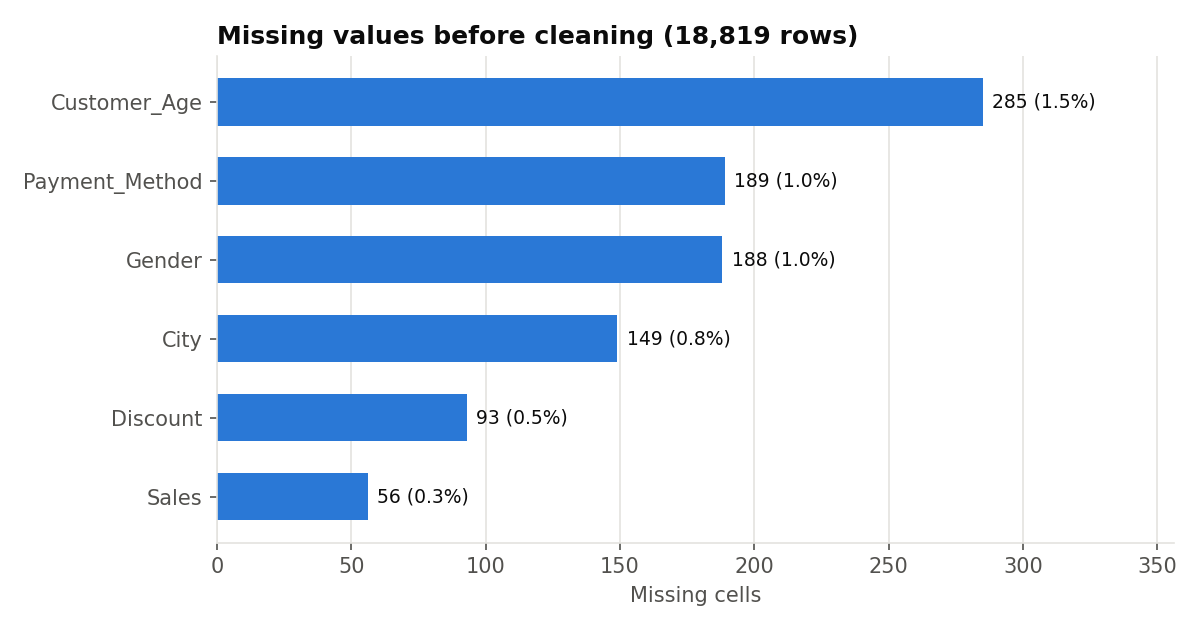

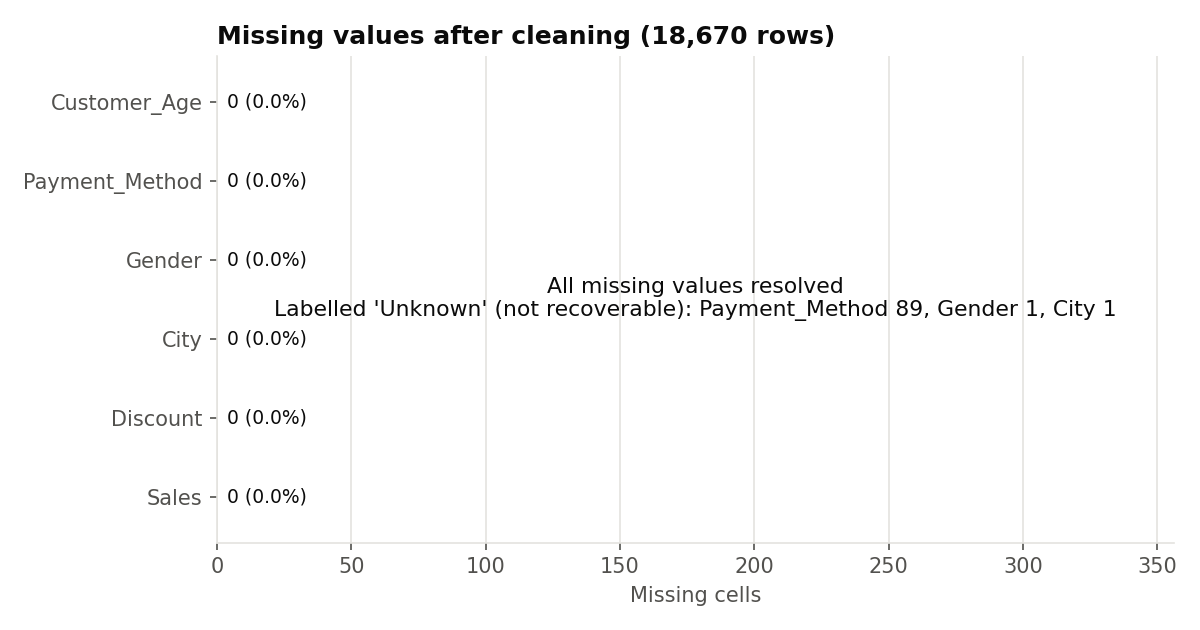

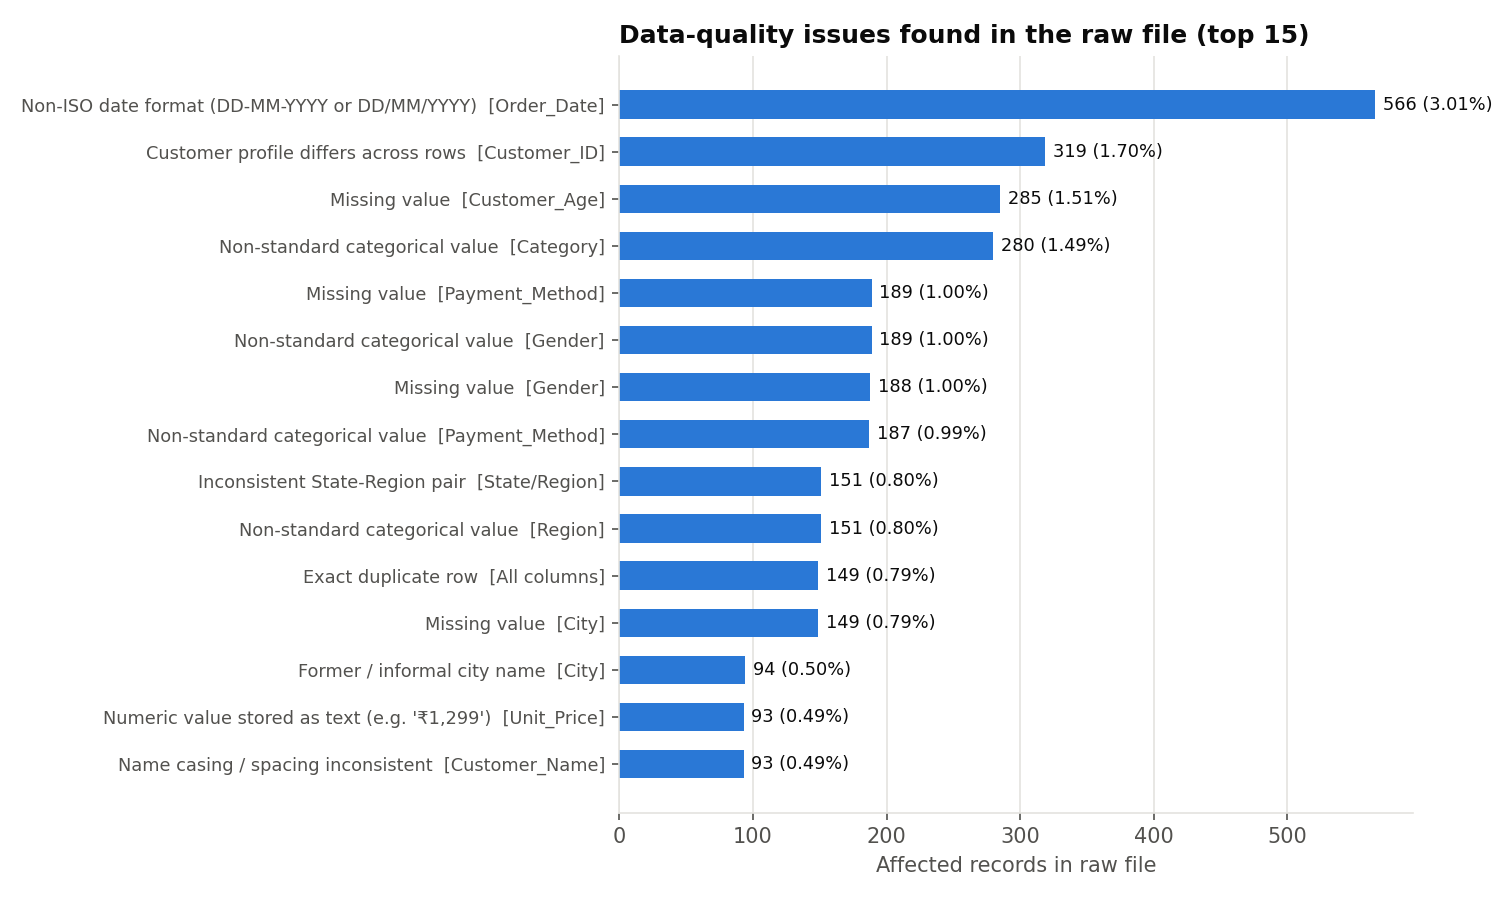

In [26]:
for f in ["01_missing_values_before.png", "02_missing_values_after.png", "04_data_quality_issue_summary.png"]:
    display(Image(str(config.DQ_FIGURES_DIR / f)))

## 15. Final checks

In [27]:
clean = pd.read_csv(config.CLEAN_DATA_FILE, encoding="utf-8-sig")
checks = {
    "Rows": len(clean),
    "Missing cells in 23 source columns": int(clean[config.EXPECTED_COLUMNS].isna().sum().sum()),
    "Duplicate Order_Line_ID": int(clean["Order_Line_ID"].duplicated().sum()),
    "Revenue formula failures": int((~clean["Revenue_Check_Pass"]).sum()),
    "Profit formula failures": int((~clean["Profit_Check_Pass"]).sum()),
    "Discount outside 0-0.40": int((~clean["Discount"].between(0, 0.40)).sum()),
    "Age outside 18-100": int((~clean["Customer_Age"].between(18, 100)).sum()),
    "Cities mapped to >1 state": int((clean.groupby("City")["State"].nunique() > 1).sum()),
    "Customers with >1 profile": int((clean.groupby("Customer_ID")[["Customer_Name", "Customer_Age", "Gender", "City"]].nunique() > 1).any(axis=1).sum()),
}
pd.Series(checks, name="Value").to_frame()

,Value
Rows,18670
Missing cells in 23 source columns,0
Duplicate Order_Line_ID,0
Revenue formula failures,0
Profit formula failures,0
Discount outside 0-0.40,0
Age outside 18-100,0
Cities mapped to >1 state,0
Customers with >1 profile,0


**Result:** the cleaned dataset is analysis-ready. Next, run `python src/database.py` to load it into SQLite. That load acts as a final validation gate, because the schema's CHECK and foreign-key constraints reject any row that breaks a business rule.